In [1]:
from datetime import datetime
import functools
import numpy as np
import pickle as pkl
import qiskit as qk
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm

import sys
sys.path.append("../")

import pulse_simulator as ps

import matplotlib.pyplot as plt

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


# Backend

In [2]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_duration = 225  # dt

# Gate time in SI units (granularity restriction)
duration = ps.qiskit_closest_multiple_of_16(desired_duration * dt / ns, backend)

# Load gatesets

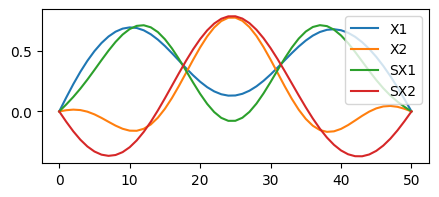

In [3]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
knames = ["X1", "X2", "SX1", "SX2"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}

fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico_a.items():
    ax.plot(v, label=k)
ax.legend()

In [4]:
# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration, v, f"custom-{k}")

In [6]:
# ...Re-run is fast due to cached envelopes
y_gates = {}
for k, v in pico_a.items():
    y_gates[k] = ps.scalable_symbolic_pulse(
        duration, v, f"custom-{k}-π/2", angle=np.pi / 2
    )

# y_gates["X1"].draw()

In [18]:
cal_x_gates = {}
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )

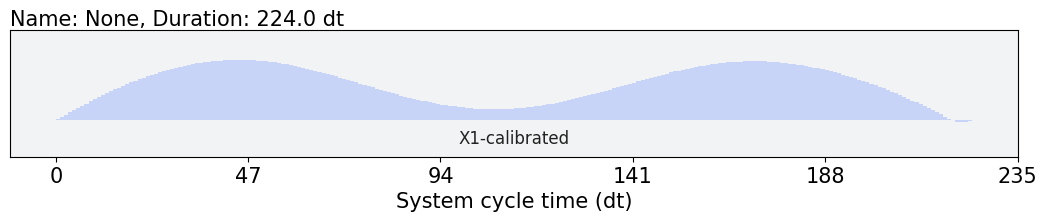

In [8]:
cal_x_gates['X1'].draw()

In [10]:
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4)
    else:
        default_gates[k] = ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2)

# default_gates["X1"].draw()

# Build the model

In [64]:
registers = [0, 1]

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# # Isolate T1 from T2
# for k in [k for k in cvars.keys() if 't2' in k]:
#     cvars.pop(k)

# Carrier frequencies of each control line
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=False,
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

H_xtalk = ps.crosstalk_model(registers, ps.backend_edges(backend), cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel
    As_static += Ajs_static

In [65]:
# Get the carriers
registered_carriers = {c: carriers[c] for c in Hs_channels}
cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

The dephasing operators are too big relative to crosstalk!

In [66]:
np.max(H_xtalk), np.max(As_static)

((0.00014891564337624234+0j), (0.0030550504633038936+0j))

### T1 Test

We will use this to interpolate for coherence limits.

In [67]:
# Test T1
t1_solver = qk_d.Solver(
    static_hamiltonian=H_drift.data,
    hamiltonian_operators=[2*H for H in Hs_control],
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=H_drift,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)


In [68]:
# The T1 time of the qubit (fixed to be the same for all qubits)
t1_duration = int(cvars['t1q0'] / dt)

with qk.pulse.build(backend=backend, name="t1-robust") as t1_sched_robust:
    qk.pulse.play(cal_x_gates["X2"], qk.pulse.DriveChannel(0))
    qk.pulse.play(ps.zero_envelope(t1_duration), qk.pulse.DriveChannel(0))

    qk.pulse.play(cal_x_gates["X1"], qk.pulse.DriveChannel(1))
    qk.pulse.play(ps.zero_envelope(t1_duration), qk.pulse.DriveChannel(1))


with qk.pulse.build(backend=backend, name="t1-default") as t1_sched_default:
    qk.pulse.play(default_gates["X2"], qk.pulse.DriveChannel(0))
    qk.pulse.play(ps.zero_envelope(t1_duration), qk.pulse.DriveChannel(0))

    qk.pulse.play(default_gates["X1"], qk.pulse.DriveChannel(1))
    qk.pulse.play(ps.zero_envelope(t1_duration), qk.pulse.DriveChannel(1))


t1_sched = [t1_sched_robust] + [t1_sched_default]

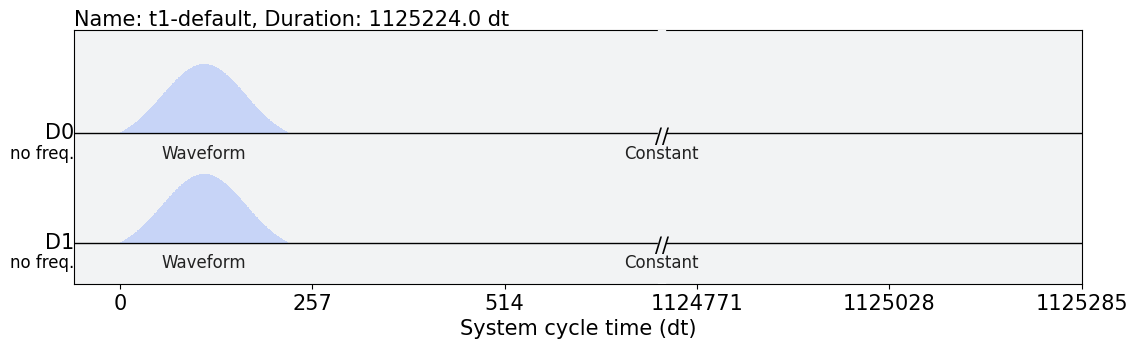

In [69]:
t1_sched[1].draw()

In [70]:
# Start in excited state of 1 qubit
ρ1 = qk.quantum_info.DensityMatrix([0, 0, 0, 1])
# ρ1 = qk.quantum_info.DensityMatrix([0, 0, 1, 0])
ρ0 = qk.quantum_info.DensityMatrix([1, 0, 0, 0])

t1_eval = np.array([(t * t1_duration / 10) * dt for t in range(11)])

t1_results = t1_solver.solve(
    t_span=[0., duration * dt + t1_duration * dt], 
    t_eval=duration * dt + t1_eval, 
    y0=ρ0, 
    signals=t1_sched,
    atol=1e-12,
    rtol=1e-12,
    method='jax_odeint'
)

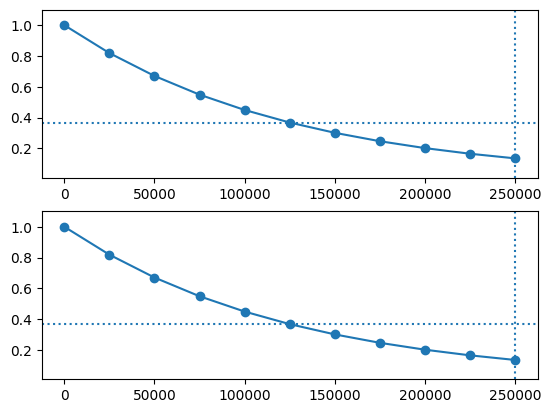

In [71]:
# NOTE: If you run the experiment in parallel, decoherence is doubled.

fig, axes = plt.subplots(2, 1)

t1_fids = []
for i, ax in enumerate(axes):
    t1_fids.append([qk.quantum_info.state_fidelity(y, ρ1) for y in t1_results[i].y])
    ax.plot(t1_eval, t1_fids[-1], marker='o')
    ax.axhline(1 / np.e, ls=':')
    ax.axvline(cvars['t1q0'], ls=':')
    # ax.set_yscale('log')
    ax.set_ylim([1e-2, 1.1])

In [72]:
def coherence_limit_robust(x: list | np.ndarray, fidelity=t1_fids[0]):
    return 1 - np.interp(duration * dt * np.array(x),  t1_eval, fidelity)

def coherence_limit_default(x: list | np.ndarray, fidelity=t1_fids[1]):
    return 1 - np.interp(duration * dt * np.array(x),  t1_eval, fidelity)

# Solvers

In [73]:
# Identity matrix
U0 = ps.qiskit_identity_operator(len(registers))
C0 = qk.quantum_info.SuperOp(U0)

In [74]:
# NOTE: Converting to a rotating frame leads to factor of 1/2 on controls.
solver= qk_d.Solver(
    static_hamiltonian=H_drift.data + H_xtalk.data,
    hamiltonian_operators=[2*H for H in Hs_control],
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=H_drift,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver1 = qk_d.Solver(
    static_hamiltonian=H_drift.data + H_xtalk.data,
    hamiltonian_operators=[2*H for H in Hs_control],
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=H_drift,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver0 = qk_d.Solver(
    static_hamiltonian=H_drift.data,
    hamiltonian_operators=[2*H for H in Hs_control],
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=H_drift,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Schedules

In [75]:
def build_pulse_schedule(list_of_moments, gateset, name, backend):
    """
    Build a pulse schedule from a circuit and a gateset.

    The circuit is specified as a list of moments, and a moment
    is a dictionary of {qubit: gate} pairs.
    """
    with qk.pulse.build(name=f"{name}", backend=backend) as schedule:
        for moment in list_of_moments:
            for qubit, gate_label in moment.items():
                channel = qk.pulse.DriveChannel(qubit)
                if "Y" in gate_label:
                    qk.pulse.shift_phase(np.pi / 2, channel)
                    qk.pulse.play(gateset[gate_label.replace("Y", "X")], channel)
                    qk.pulse.shift_phase(-np.pi / 2, channel)
                else:
                    qk.pulse.play(gateset[gate_label], channel)
    return schedule

# Example 1: XYXY

In [76]:
sim_name = "XYXY-1-5"
layers = range(1, 6)

# List of durations corresponding to the layers
# t_eval = [duration * dt * (2 * m - 1) for m in layers]
t_eval = [duration * dt * (4 * m) for m in layers]

robust_schedules = []
for n in layers:
    # moments = [{0: "X1", 1: "X2"}]
    # moments += moments * (2 * (n - 1))
    moments = []
    moments +=  [{0: "X1", 1: "Y2"}, {0: "Y1", 1: "X2"}, {0: "X1", 1: "Y2"}, {0: "Y1", 1: "X2"}] * n
    sched = build_pulse_schedule(moments, cal_x_gates, f"robust-{len(moments)}", backend)
    robust_schedules.append(sched)


default_schedules = []
for n in layers:
    # moments = [{0: "X1", 1: "X2"}] 
    # moments += moments * (2 * (n - 1))
    moments = []
    moments +=  [{0: "X1", 1: "Y2"}, {0: "Y1", 1: "X2"}, {0: "X1", 1: "Y2"}, {0: "Y1", 1: "X2"}] * n
    sched = build_pulse_schedule(
        moments, default_gates, f"default-{len(moments)}", backend
    )
    default_schedules.append(sched)

sched_keys = ["robust", "default"]
schedules = robust_schedules + default_schedules

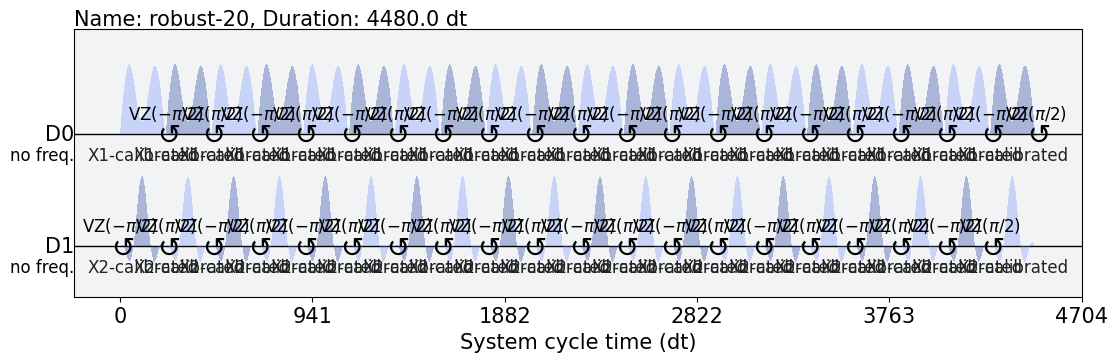

In [77]:
robust_schedules[-1].draw()

In [78]:
print("Runtime of longest circuit: ", max(t_eval), "ns")

Runtime of longest circuit:  995.5555555555554 ns


In [79]:
# NOTE: sometimes there is a leak and you need to reconstruct the solver

solver.model.evaluation_mode = 'sparse_vectorized'
y0 = C0

results = solver.solve(
    t_span=[0., max(t_eval)], 
    t_eval=t_eval, 
    y0=y0, 
    signals=schedules,
    atol=1e-12,
    rtol=1e-12,
    method='jax_odeint'
)

KeyboardInterrupt: 

In [ ]:
solver0.model.evaluation_mode = 'sparse'
y0 = U0

results0 = solver0.solve(
    t_span=[0., max(t_eval)], 
    t_eval=t_eval, 
    y0=y0, 
    signals=schedules,
    atol=1e-12,
    rtol=1e-12,
    method='jax_odeint'
)

In [ ]:
solver.model.evaluation_mode = 'sparse'
y0 = U0

results1 = solver1.solve(
    t_span=[0., max(t_eval)], 
    t_eval=t_eval, 
    y0=y0,
    signals=schedules,
    atol=1e-12,
    rtol=1e-12,
    method='jax_odeint'
)

In [ ]:
# stamp = datetime.now().isoformat(timespec='seconds')
# with open(f'../playground/{stamp}_sim_{sim_name}.pkl','wb') as file:
#     pkl.dump([results, results0, results1], file)

Compute fidelity (set the target and the x axis)

In [ ]:
# x values & target
# target = ps.from_label("XX")
# x = [2 * i - 1 for i in layers]

target = ps.from_label("II")
x = [4 * i for i in layers]

# y values
fidelity = []
for n, sol in enumerate(results):
    fidelity += [qk.quantum_info.process_fidelity(
        sol.y[n % len(t_eval)], 
    )]
f = 1 - np.reshape(fidelity, (2, len(layers)))

fidelity0 = []
for n, sol in enumerate(results0):
    fidelity0 += [qk.quantum_info.process_fidelity(
        sol.y[n % len(t_eval)], target
    )]
f0 = 1 - np.reshape(fidelity0, (2, len(layers)))

fidelity1 = []
for n, sol in enumerate(results1):
    fidelity1 += [qk.quantum_info.process_fidelity(
        sol.y[n % len(t_eval)], target
    )]
f1 = 1 - np.reshape(fidelity1, (2, len(layers)))

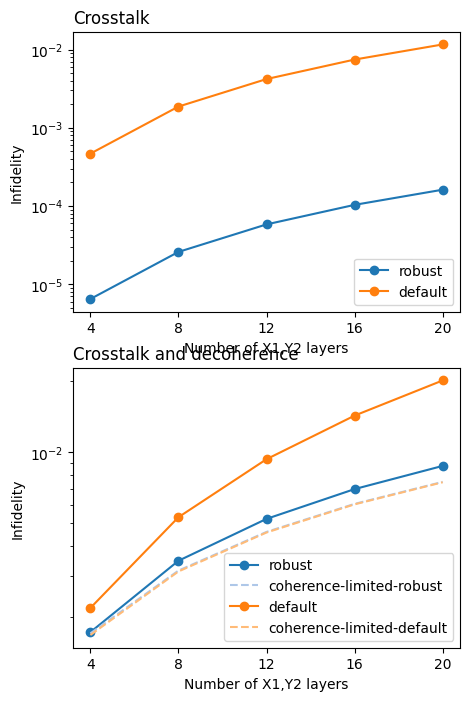

In [ ]:
plt.rcParams["axes.titley"] = 1.0

fig, axes = plt.subplots(2, 1, figsize=(5, 8))

ax = axes[1]
ax.set_title("Crosstalk and decoherence", loc="left")
colors = plt.get_cmap("tab20")
for i, (k, y) in enumerate(zip(sched_keys, f)):
    ax.plot(x, y, marker="o", label=k, color=colors(2 * i))

    cy = coherence_limit_robust(x) if "robust" in k else coherence_limit_default(x)
    ax.plot(
        x,
        cy,
        label=f"coherence-limited-{k}",
        ls='--',
        color=colors(2 * i + 1),
    )

    # coherence_limit = 1 - np.interp(duration * dt * np.array(x),  t1_eval, t1_fids)
    # # Rescale the coherence limit to the original gate fidelity
    # ax.plot(x, y[0] / coherence_limit[0] * coherence_limit,
    #         lw=1, ls='--', label=f"coherence-limited-{k}", color=colors(2 * i + 1))


ax = axes[0]
ax.set_title("Crosstalk", loc="left")
colors = plt.get_cmap("tab20")
for i, (k, y) in enumerate(zip(sched_keys, f1)):
    ax.plot(x, y, marker="o", label=k, color=colors(2 * i))

# Titles
for ax in axes:
    ax.set_xlabel("Number of X1,Y2 layers")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_ylabel("Infidelity")
    # ax.legend(loc="center left")
    ax.legend(loc="lower right")

### Other plots

# Example 2: Hamiltonian simulation

In [14]:
desired_duration2 = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration2 = ps.qiskit_closest_multiple_of_16(desired_duration2 * dt / ns, backend)

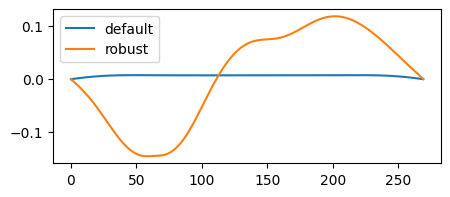

In [11]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

In [15]:
# The initial run takes awhile to construct the symbolic pulse shapes
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration2,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

In [19]:
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )

In [ ]:
def build_pulse_schedule_v2(list_of_moments, gateset, cr_gate, name, backend):
    """
    Build a pulse schedule from a circuit and a gateset.

    The circuit is specified as a list of moments, and a moment
    is a dictionary of {qubit: gate} pairs.
    """
    with qk.pulse.build(name=f"{name}", backend=backend) as schedule:
        for moment in list_of_moments:
            for qubit, gate_label in moment.items():
                if len(qubit) == 1:
                    # One qubit gate
                    drive_channel = ps.get_drive_channel(qubit, backend)
                    if "Y" in gate_label:
                        qk.pulse.shift_phase(np.pi / 2, channel)
                        qk.pulse.play(gateset[gate_label.replace("Y", "X")], channel)
                        qk.pulse.shift_phase(-np.pi / 2, channel)
                    else:
                        qk.pulse.play(gateset[gate_label], channel)
                else:
                    # Two qubit gate
                    q0, q1 = qubit
                    drive_channel = ps.get_drive_channel(q0, backend)
                    control_channel = ps.get_control_channel(q0, q1, backend)
                    qk.pulse.play(cr_gate, control_channel)
                    if q0 % 2 == 0:
                        qk.pulse.play(gateset["X1"])
                    else:
                        qk.pulse.play(gateset["X2"])
                    # Flip sign
                    qk.pulse.shift_phase(np.pi, channel)
                    qk.pulse.play(cr_gate, control_channel)
                    qk.pulse.shift_phase(-np.pi, channel)
    return schedule

In [ ]:
                # control channel is for R_ZX
                qiskit.pulse.play(zx_p, control_channel)
                qiskit.pulse.play(
                    qiskit.pulse.Constant(x.duration, 0.0), control_channel
                )
                qiskit.pulse.play(zx_n, control_channel)

                # drive channel is for R_X
                qiskit.pulse.play(
                    qiskit.pulse.Constant(zx_p.duration, 0.0), drive_channel
                )
                qiskit.pulse.play(x, drive_channel)
                qiskit.pulse.play(
                    qiskit.pulse.Constant(zx_n.duration, 0.0), drive_channel
                )